# Pipeline Điểm danh Nhận diện Khuôn mặt (Domain: CASIA-WebFace & CASIA-FASD)
Sử dụng `buffalo_s` cho Face Recognition và `MiniFASNetV2` cho Anti-Spoofing.

In [1]:
!pip install insightface onnxruntime albumentations matplotlib opencv-python
!git clone https://github.com/minivision-ai/Silent-Face-Anti-Spoofing.git

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 13.8 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 67.5 MB/s eta 0:00:00:00:0100:01
Cloning into 'Silent-Face-Anti-Spoofing'...
remote: Enumerating objects: 376, done.
remote: Counting objects: 100% (116/116), done.
remote: Compressing objects: 100% (31/31), done.
remote: Total 376 (delta 92), reused 85 (delta 85), pack-reused 260 (from 2)
Receiving objects: 100% (376/376), 26.04 MiB | 47.53 MiB/s, done.
Resolving deltas: 100% (166/166), done.


## 1. Chuẩn bị Dữ liệu (CASIA-WebFace và CASIA-FASD)
Trích xuất ảnh người thật từ WebFace để test định danh, và lấy ảnh thật/giả từ FASD để test Liveness.

Đã nạp thành công ảnh từ ID: 000000 và 000001


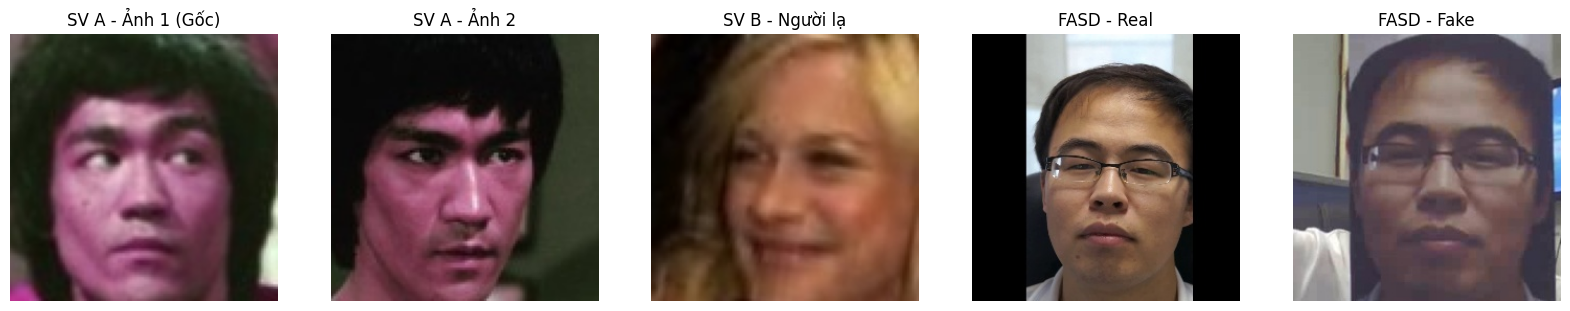

In [2]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. ĐỌC CASIA-WEBFACE TỪ THƯ MỤC ẢNH
# Cập nhật đường dẫn dựa trên ảnh bạn chụp
webface_dir = '/kaggle/input/datasets/ntl0601/casia-webface/casia-webface' 

# Lấy danh sách các thư mục con (mỗi thư mục là 1 ID) và sắp xếp theo thứ tự
id_folders = sorted([f.path for f in os.scandir(webface_dir) if f.is_dir()])

if len(id_folders) >= 2:
    # Chọn 2 người đầu tiên làm Sinh viên A và Sinh viên B
    sv_A_folder = id_folders[0]
    sv_B_folder = id_folders[1]

    # Lấy danh sách đường dẫn ảnh bên trong mỗi folder
    sv_A_images = sorted(glob.glob(os.path.join(sv_A_folder, '*.jpg')))
    sv_B_images = sorted(glob.glob(os.path.join(sv_B_folder, '*.jpg')))

    # Đọc ảnh và chuyển hệ màu từ BGR (OpenCV) sang RGB để vẽ bằng Matplotlib
    img_svA_1 = cv2.cvtColor(cv2.imread(sv_A_images[0]), cv2.COLOR_BGR2RGB)
    img_svA_2 = cv2.cvtColor(cv2.imread(sv_A_images[1]), cv2.COLOR_BGR2RGB)
    img_svB = cv2.cvtColor(cv2.imread(sv_B_images[0]), cv2.COLOR_BGR2RGB)
    
    print(f"Đã nạp thành công ảnh từ ID: {os.path.basename(sv_A_folder)} và {os.path.basename(sv_B_folder)}")
else:
    print("Lỗi: Không tìm thấy thư mục ID nào. Hãy kiểm tra lại đường dẫn webface_dir.")

# 2. ĐỌC CASIA-FASD (Phần này giữ nguyên)
fasd_color_dir = '/kaggle/input/datasets/minhnh2107/casiafasd/train_img/train_img/color'
real_files = glob.glob(os.path.join(fasd_color_dir, '*real*.jpg'))
fake_files = glob.glob(os.path.join(fasd_color_dir, '*fake*.jpg'))

real_fasd_img = cv2.cvtColor(cv2.imread(real_files[0]), cv2.COLOR_BGR2RGB) if real_files else None
fake_fasd_img = cv2.cvtColor(cv2.imread(fake_files[0]), cv2.COLOR_BGR2RGB) if fake_files else None

# Hiển thị tổng quan Dataset đã lấy
fig, ax = plt.subplots(1, 5, figsize=(20, 4))
ax[0].imshow(img_svA_1); ax[0].set_title('SV A - Ảnh 1 (Gốc)'); ax[0].axis('off')
ax[1].imshow(img_svA_2); ax[1].set_title('SV A - Ảnh 2'); ax[1].axis('off')
ax[2].imshow(img_svB); ax[2].set_title('SV B - Người lạ'); ax[2].axis('off')
if real_fasd_img is not None: 
    ax[3].imshow(real_fasd_img); ax[3].set_title('FASD - Real'); ax[3].axis('off')
if fake_fasd_img is not None:
    ax[4].imshow(fake_fasd_img); ax[4].set_title('FASD - Fake'); ax[4].axis('off')
plt.show()

## 2. Tìm khuôn mặt và Căn chỉnh (InsightFace - buffalo_s)
Thử nghiệm trên ảnh Sinh viên A từ CASIA-WebFace.

download_path: /root/.insightface/models/buffalo_s


100%|██████████| 124617/124617 [00:01<00:00, 112166.03KB/s]


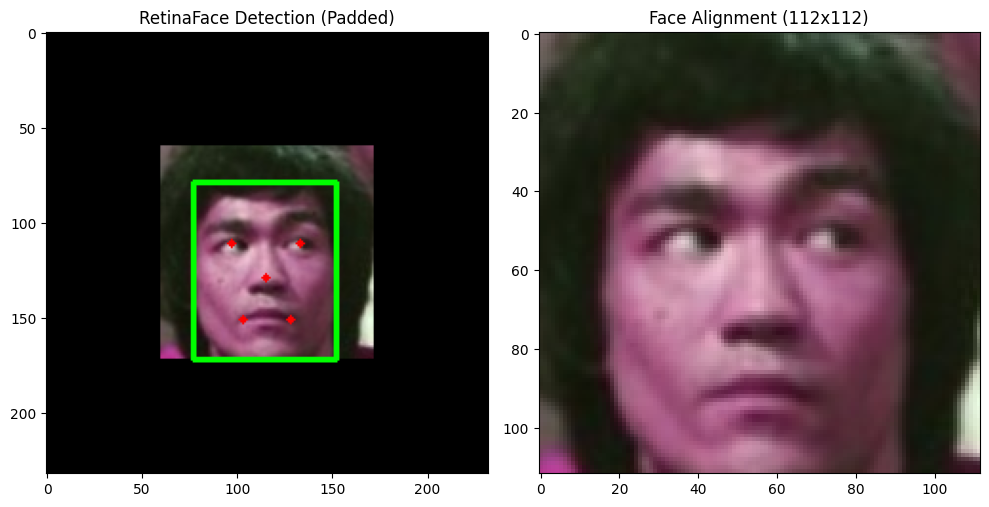

In [3]:
from insightface.app import FaceAnalysis
from insightface.utils import face_align
import cv2
import matplotlib.pyplot as plt

# Khởi tạo model mạnh (buffalo_s) và hạ ngưỡng phát hiện xuống 0.15
app = FaceAnalysis(name='buffalo_s')
app.prepare(ctx_id=0, det_size=(640, 640), det_thresh=0.15)

# Đọc ảnh và chuyển sang BGR
img_bgr = cv2.cvtColor(img_svA_1, cv2.COLOR_RGB2BGR)

# THỦ THUẬT: Thêm viền đen (Padding) 60 pixel mỗi cạnh để tạo không gian cho RetinaFace
img_padded = cv2.copyMakeBorder(img_bgr, 60, 60, 60, 60, cv2.BORDER_CONSTANT, value=[0, 0, 0])

# Đưa ảnh đã pad qua mô hình
faces = app.get(img_padded)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

if faces:
    face_svA = faces[0]
    emb_svA_goc = face_svA.normed_embedding # Vector 512 chiều gốc của SV A
    
    bbox = face_svA.bbox.astype(int)
    kps = face_svA.kps
    
    img_vis = img_padded.copy()
    cv2.rectangle(img_vis, (bbox[0], bbox[1]), (bbox[2], bbox[3]), (0, 255, 0), 2)
    for p in kps:
        cv2.circle(img_vis, (int(p[0]), int(p[1])), 2, (0, 0, 255), -1)
        
    aligned_face = face_align.norm_crop(img_padded, landmark=kps)
    
    ax[0].imshow(cv2.cvtColor(img_vis, cv2.COLOR_BGR2RGB))
    ax[0].set_title('RetinaFace Detection (Padded)')
    
    ax[1].imshow(cv2.cvtColor(aligned_face, cv2.COLOR_BGR2RGB))
    ax[1].set_title('Face Alignment (112x112)')
else:
    print('Vẫn không tìm thấy khuôn mặt.')
    ax[0].imshow(cv2.cvtColor(img_padded, cv2.COLOR_BGR2RGB))
    ax[0].set_title('Detection (Không có mặt)')
    ax[1].text(0.5, 0.5, 'N/A', ha='center', va='center', fontsize=14, color='red')
    ax[1].axis('off')

plt.tight_layout()
plt.show()

## 3. Kiểm thử Định danh (Recognition) & Augmentation
Đo độ tương đồng (Cosine Similarity) giữa vector ảnh gốc của SV A với:
1. Ảnh thứ 2 của SV A (Kỳ vọng: Điểm cao > 60-70%)
2. Ảnh của SV B (Kỳ vọng: Điểm thấp < 10%)
3. Các ảnh SV A bị bóp méo, nhiễu màu (Kỳ vọng: Điểm vẫn vượt ngưỡng).

--- ĐÁNH GIÁ CHÉO CÁC ID KHÁC NHAU ---
Cùng Sinh viên A (2 ảnh khác nhau) -> Cosine Sim: 71.26%
Sinh viên A vs Sinh viên B (Người lạ) -> Cosine Sim: 0.05%

--- ĐÁNH GIÁ AUGMENTATION TRÊN ẢNH SV A ---


/tmp/ipykernel_58/531761210.py:41: UserWarning: Argument(s) 'fill_value' are not valid for transform CoarseDropout
  'Occlusion (Che khuất)': A.Compose([A.CoarseDropout(num_holes_range=(1, 2), hole_height_range=(20, 40), hole_width_range=(20, 40), fill_value=0, p=1.0)]),
/tmp/ipykernel_58/531761210.py:42: UserWarning: Argument(s) 'cval' are not valid for transform Affine
  'Perspective (Góc lệch)': A.Compose([A.Affine(scale=(0.95, 1.05), translate_percent=(-0.05, 0.05), rotate=(-15, 15), p=1.0, cval=0)])


Distortion (Bóp méo)      | 91.77%
Color Jitter (Sai màu)    | 95.20%
Occlusion (Che khuất)     | 89.55%
Perspective (Góc lệch)    | 93.98%


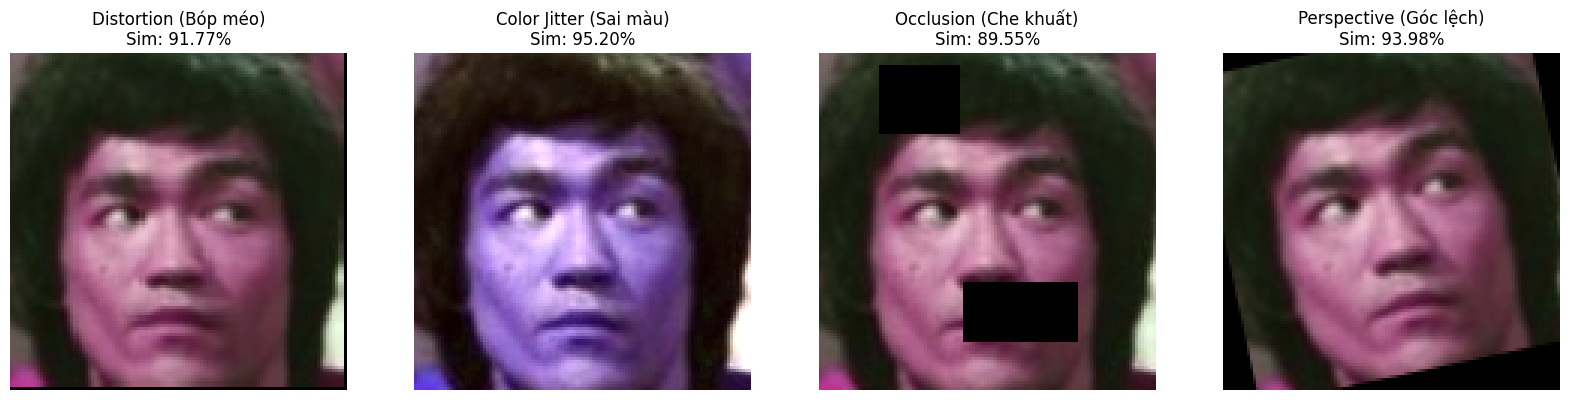

In [4]:
import albumentations as A
from numpy.linalg import norm
import numpy as np
import cv2
import matplotlib.pyplot as plt

def get_embedding(img_rgb):
    # 1. Chuyển sang BGR
    img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    
    # 2. BẮT BUỘC THÊM PADDING: Viền đen 60px để mô hình nhận diện được ảnh cắt sát
    img_padded = cv2.copyMakeBorder(img_bgr, 60, 60, 60, 60, cv2.BORDER_CONSTANT, value=[0, 0, 0])
    
    # 3. Đưa ảnh đã pad qua mô hình
    res = app.get(img_padded)
    if res:
        return res[0].normed_embedding
    return None

def cos_sim(e1, e2):
    if e1 is None or e2 is None: return 0.0
    return np.dot(e1, e2) / (norm(e1) * norm(e2))

# Trích xuất vector (Lúc này hàm get_embedding đã tự động thêm viền)
emb_svA_goc = get_embedding(img_svA_1)
emb_svA_2 = get_embedding(img_svA_2)
emb_svB = get_embedding(img_svB)

if emb_svA_goc is None:
    print("❌ LỖI: Vẫn không tìm thấy khuôn mặt ảnh gốc! Hãy kiểm tra lại det_thresh ở cell trên.")
else:
    print("--- ĐÁNH GIÁ CHÉO CÁC ID KHÁC NHAU ---")
    print(f"Cùng Sinh viên A (2 ảnh khác nhau) -> Cosine Sim: {cos_sim(emb_svA_goc, emb_svA_2)*100:.2f}%")
    print(f"Sinh viên A vs Sinh viên B (Người lạ) -> Cosine Sim: {cos_sim(emb_svA_goc, emb_svB)*100:.2f}%")
    
    print("\n--- ĐÁNH GIÁ AUGMENTATION TRÊN ẢNH SV A ---")
    # Đã cập nhật tham số chuẩn của bản Albumentations mới nhất để triệt tiêu cảnh báo đỏ
    transforms = {
        'Distortion (Bóp méo)': A.Compose([A.GridDistortion(num_steps=5, distort_limit=0.15, p=1.0)]),
        'Color Jitter (Sai màu)': A.Compose([A.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.4, hue=0.2, p=1.0)]),
        'Occlusion (Che khuất)': A.Compose([A.CoarseDropout(num_holes_range=(1, 2), hole_height_range=(20, 40), hole_width_range=(20, 40), fill_value=0, p=1.0)]),
        'Perspective (Góc lệch)': A.Compose([A.Affine(scale=(0.95, 1.05), translate_percent=(-0.05, 0.05), rotate=(-15, 15), p=1.0, cval=0)])
    }
    
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    for i, (name, t) in enumerate(transforms.items()):
        # Tạo ảnh nhiễu từ ảnh gốc
        aug_img = t(image=img_svA_1)['image']
        
        # Đưa đi trích xuất (hàm đã tự động pad viền đen)
        emb_aug = get_embedding(aug_img)
        
        # Tính độ tương đồng
        sim = cos_sim(emb_svA_goc, emb_aug)
        print(f"{name:<25} | {sim*100:.2f}%")
        
        axes[i].imshow(aug_img)
        axes[i].set_title(f'{name}\nSim: {sim*100:.2f}%')
        axes[i].axis('off')
    plt.show()

In [5]:
import sys
import warnings
warnings.filterwarnings('ignore')

original_dir = os.getcwd()

try:
    if not os.getcwd().endswith('Silent-Face-Anti-Spoofing'):
        os.chdir('Silent-Face-Anti-Spoofing')
        
    sys.path.append('.')
    from src.anti_spoof_predict import AntiSpoofPredict
    from src.generate_patches import CropImage
    from src.utility import parse_model_name

    model_path = './resources/anti_spoof_models/2.7_80x80_MiniFASNetV2.pth'
    anti_spoof = AntiSpoofPredict(0) 
    image_cropper = CropImage()

    def check_liveness(img_rgb):
        if img_rgb is None: return "Lỗi: Không có ảnh", 0.0
        img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
        image_bbox = anti_spoof.get_bbox(img_bgr)
        
        model_name = model_path.split('/')[-1]
        h_input, w_input, model_type, scale = parse_model_name(model_name)
        param = {
            'org_img': img_bgr, 'bbox': image_bbox, 'scale': scale,
            'out_w': w_input, 'out_h': h_input, 'crop': True
        }
        
        img_crop = image_cropper.crop(**param)
        pred = anti_spoof.predict(img_crop, model_path)
        label = np.argmax(pred)
        return 'Real Face' if label == 1 else 'Fake / Spoof', pred[0][label]

    print('--- KẾT QUẢ KIỂM THỬ LIVENESS ---')
    
    res, score = check_liveness(real_fasd_img)
    print(f'1. CASIA-FASD (Ảnh Thật)   -> {res} | Score: {score:.4f}')
    
    res, score = check_liveness(fake_fasd_img)
    print(f'2. CASIA-FASD (Ảnh Giả)    -> {res} | Score: {score:.4f}')
    
    res, score = check_liveness(img_svA_1)
    print(f'3. CASIA-WebFace (Webcam)  -> {res} | Score: {score:.4f}')

finally:
    os.chdir(original_dir)

--- KẾT QUẢ KIỂM THỬ LIVENESS ---
1. CASIA-FASD (Ảnh Thật)   -> Real Face | Score: 0.9956
2. CASIA-FASD (Ảnh Giả)    -> Fake / Spoof | Score: 0.9876
3. CASIA-WebFace (Webcam)  -> Real Face | Score: 0.9528


1. ĐANG ĐÁNH GIÁ ĐỊNH DANH (RECOGNITION)...


Processing Identities: 100%|██████████| 50/50 [00:12<00:00,  3.92it/s]



=> TỔNG KẾT RECOGNITION:
   - CÙNG MỘT NGƯỜI (Intra-class):
     + Mean (Trung bình): 42.20%
     + Median (Trung vị) : 42.41%
     + Min: -10.57% | Max: 82.33%
   - HAI NGƯỜI KHÁC NHAU (Inter-class):
     + Mean (Trung bình): 1.65%
     + Median (Trung vị) : 1.59%
     + Min: -11.43% | Max: 11.54%

2. ĐANG ĐÁNH GIÁ LIVENESS (ANTI-SPOOFING)...


Processing Liveness: 100%|██████████| 1655/1655 [03:18<00:00,  8.35it/s]



=> TỔNG KẾT LIVENESS:
   - ẢNH THẬT (Kỳ vọng điểm gần 100%):
     + Mean (Trung bình): 82.17%
     + Median (Trung vị) : 98.14%
     + Min: 0.01% | Max: 100.00%
   - ẢNH GIẢ (Kỳ vọng điểm gần 0%):
     + Mean (Trung bình): 3.60%
     + Median (Trung vị) : 0.06%
     + Min: 0.00% | Max: 92.88%


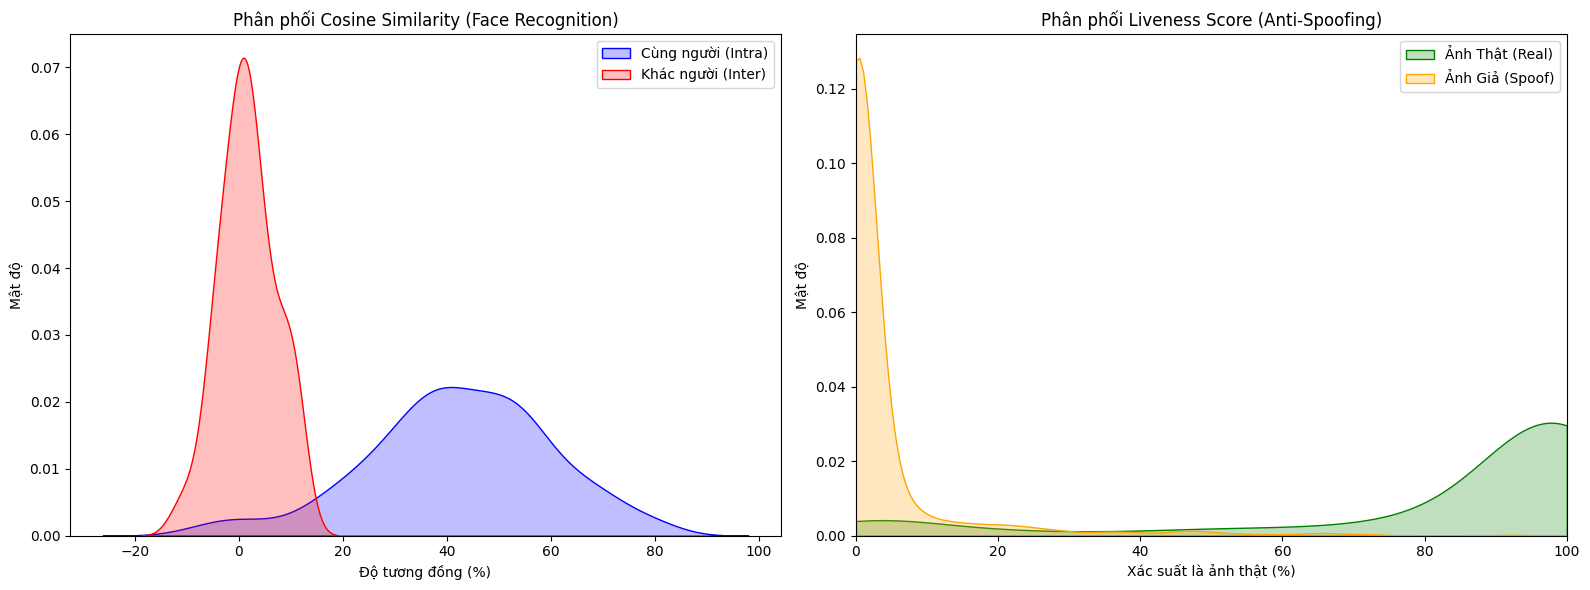

In [6]:
import os
import glob
import cv2
import numpy as np
from numpy.linalg import norm
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Hàm in thống kê
def print_stats(name, data):
    if not data: return
    print(f"   - {name}:")
    print(f"     + Mean (Trung bình): {np.mean(data):.2f}%")
    print(f"     + Median (Trung vị) : {np.median(data):.2f}%")
    print(f"     + Min: {np.min(data):.2f}% | Max: {np.max(data):.2f}%")

# Lấy mô hình Encode trực tiếp (Khắc phục lỗi điểm thấp ở WebFace)
rec_model = None
for k, v in app.models.items():
    if hasattr(v, 'get_feat'):
        rec_model = v
        break

def get_direct_embedding(img_path):
    img_bgr = cv2.imread(img_path)
    if img_bgr is None: return None
    img_112 = cv2.resize(img_bgr, (112, 112))
    feat = rec_model.get_feat(img_112)
    if feat is None or len(feat) == 0: return None
    emb = feat[0].flatten()
    return emb / norm(emb)

# ==========================================
# PHẦN 1: ĐÁNH GIÁ FACE RECOGNITION
# ==========================================
print("1. ĐANG ĐÁNH GIÁ ĐỊNH DANH (RECOGNITION)...")
webface_dir = '/kaggle/input/datasets/ntl0601/casia-webface/casia-webface'
id_folders = sorted([f.path for f in os.scandir(webface_dir) if f.is_dir()])

intra_scores = []
inter_scores = []

for i, folder in enumerate(tqdm(id_folders[:50], desc="Processing Identities")):
    img_paths = sorted(glob.glob(os.path.join(folder, '*.jpg')))
    if len(img_paths) < 2: continue
    
    emb_ref = get_direct_embedding(img_paths[0])
    if emb_ref is None: continue
        
    # Intra-class (Cùng người)
    for test_path in img_paths[1:10]: 
        emb_test = get_direct_embedding(test_path)
        if emb_test is not None:
            intra_scores.append(np.dot(emb_ref, emb_test) * 100)
            
    # Inter-class (Khác người - lấy người tiếp theo)
    if i < len(id_folders) - 1:
        stranger_paths = sorted(glob.glob(os.path.join(id_folders[i+1], '*.jpg')))
        emb_stranger = get_direct_embedding(stranger_paths[0])
        if emb_stranger is not None:
            inter_scores.append(np.dot(emb_ref, emb_stranger) * 100)

print("\n=> TỔNG KẾT RECOGNITION:")
print_stats("CÙNG MỘT NGƯỜI (Intra-class)", intra_scores)
print_stats("HAI NGƯỜI KHÁC NHAU (Inter-class)", inter_scores)

# ==========================================
# PHẦN 2: ĐÁNH GIÁ LIVENESS (ANTI-SPOOFING)
# ==========================================
print("\n2. ĐANG ĐÁNH GIÁ LIVENESS (ANTI-SPOOFING)...")
original_dir = os.getcwd()

scores_real_imgs = [] # Điểm Liveness của ảnh Thật
scores_fake_imgs = [] # Điểm Liveness của ảnh Giả

try:
    if not os.getcwd().endswith('Silent-Face-Anti-Spoofing'):
        os.chdir('Silent-Face-Anti-Spoofing')
        
    fasd_color_dir = '/kaggle/input/datasets/minhnh2107/casiafasd/train_img/train_img/color'
    all_fasd_imgs = glob.glob(os.path.join(fasd_color_dir, '*.jpg'))
    
    for img_path in tqdm(all_fasd_imgs, desc="Processing Liveness"):
        is_real_img = 'real' in os.path.basename(img_path).lower()
        img_bgr = cv2.imread(img_path)
        image_bbox = anti_spoof.get_bbox(img_bgr)
        
        if image_bbox[0] == 0 and image_bbox[1] == 0 and image_bbox[2] == 0 and image_bbox[3] == 0:
            liveness_score = 0.0 # Không thấy mặt coi như Fake
        else:
            model_name = model_path.split('/')[-1]
            h_input, w_input, model_type, scale = parse_model_name(model_name)
            param = {'org_img': img_bgr, 'bbox': image_bbox, 'scale': scale, 'out_w': w_input, 'out_h': h_input, 'crop': True}
            img_crop = image_cropper.crop(**param)
            pred = anti_spoof.predict(img_crop, model_path)
            
            # Lấy xác suất của nhãn số 1 (Real Face)
            liveness_score = pred[0][1] * 100 
            
        if is_real_img:
            scores_real_imgs.append(liveness_score)
        else:
            scores_fake_imgs.append(liveness_score)

    print("\n=> TỔNG KẾT LIVENESS:")
    print_stats("ẢNH THẬT (Kỳ vọng điểm gần 100%)", scores_real_imgs)
    print_stats("ẢNH GIẢ (Kỳ vọng điểm gần 0%)", scores_fake_imgs)

finally:
    os.chdir(original_dir)

# ==========================================
# PHẦN 3: VẼ BIỂU ĐỒ TRỰC QUAN HÓA
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Biểu đồ 1: Face Recognition
sns.kdeplot(intra_scores, fill=True, color="blue", label="Cùng người (Intra)", ax=axes[0])
sns.kdeplot(inter_scores, fill=True, color="red", label="Khác người (Inter)", ax=axes[0])
axes[0].set_title("Phân phối Cosine Similarity (Face Recognition)")
axes[0].set_xlabel("Độ tương đồng (%)")
axes[0].set_ylabel("Mật độ")
axes[0].legend()

# Biểu đồ 2: Liveness
sns.kdeplot(scores_real_imgs, fill=True, color="green", label="Ảnh Thật (Real)", ax=axes[1], clip=(0, 100))
sns.kdeplot(scores_fake_imgs, fill=True, color="orange", label="Ảnh Giả (Spoof)", ax=axes[1], clip=(0, 100))
axes[1].set_title("Phân phối Liveness Score (Anti-Spoofing)")
axes[1].set_xlabel("Xác suất là ảnh thật (%)")
axes[1].set_ylabel("Mật độ")
axes[1].set_xlim(0, 100) # Ép trục X chỉ hiển thị từ 0 đến 100
axes[1].legend()

plt.tight_layout()
plt.show()

Đang chuẩn bị dữ liệu LFW từ thư mục local...
Đang giải nén LFW dataset...
Tổng số ảnh tìm thấy: 13233


Analyzing LFW Confidence: 100%|██████████| 300/300 [01:10<00:00,  4.27it/s]



=> TỔNG KẾT DETECTION CONFIDENCE (RETINAFACE):
   - Số khuôn mặt bắt được: 418
   - Min Score   : 0.1536
   - Max Score   : 0.9020
   - Mean Score  : 0.7375
   - Median      : 0.8318


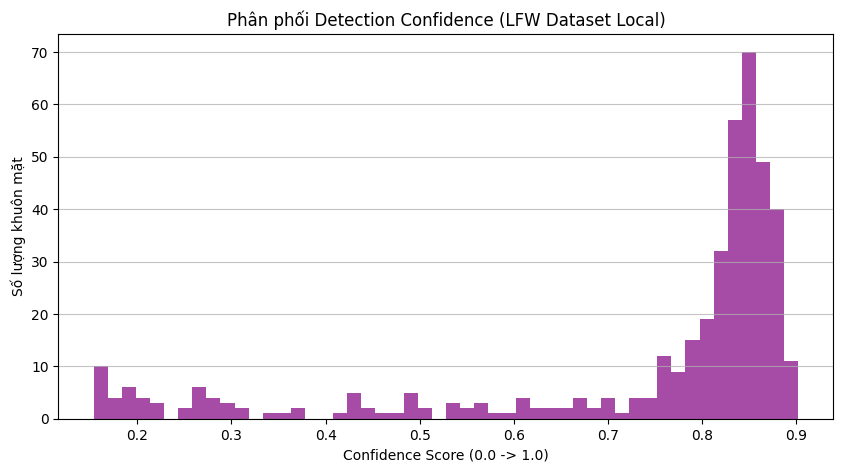

In [7]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import tarfile
import warnings
warnings.filterwarnings('ignore')

print("Đang chuẩn bị dữ liệu LFW từ thư mục local...")
lfw_archive = '/kaggle/input/datasets/atulanandjha/lfwpeople/lfw-funneled.tgz'
lfw_extract_dir = '/kaggle/working/lfw_funneled'

# Giải nén nếu chưa có (phòng hờ bạn chưa chạy cell trước đó)
if not os.path.exists(lfw_extract_dir):
    print("Đang giải nén LFW dataset...")
    with tarfile.open(lfw_archive, 'r:gz') as tar:
        tar.extractall(path='/kaggle/working/')

# Lấy danh sách tất cả các file ảnh jpg
all_lfw_imgs = glob.glob(os.path.join(lfw_extract_dir, '*/*.jpg'))
print(f"Tổng số ảnh tìm thấy: {len(all_lfw_imgs)}")

det_scores = []

# Đảm bảo hàm padding đã được khai báo
def preprocess_for_retina_test(img_bgr, target_size=(640, 640)):
    h, w = img_bgr.shape[:2]
    if h > target_size[0] or w > target_size[1]:
        scale = min(target_size[0]/h, target_size[1]/w)
        new_w, new_h = int(w * scale), int(h * scale)
        img_bgr = cv2.resize(img_bgr, (new_w, new_h))
        h, w = img_bgr.shape[:2]
    pad_h, pad_w = target_size[0] - h, target_size[1] - w
    top, bottom = pad_h // 2, pad_h - (pad_h // 2)
    left, right = pad_w // 2, pad_w - (pad_w // 2)
    return cv2.copyMakeBorder(img_bgr, top, bottom, left, right, cv2.BORDER_CONSTANT, value=[0, 0, 0])

# Quét qua 300 ảnh đầu tiên để phân tích nhánh
for img_path in tqdm(all_lfw_imgs[:300], desc="Analyzing LFW Confidence"):
    img_bgr = cv2.imread(img_path)
    if img_bgr is None: continue
    
    img_padded = preprocess_for_retina_test(img_bgr)
    faces = app.get(img_padded)
    
    # Lấy điểm det_score 
    for face in faces:
        det_scores.append(face.det_score)

if det_scores:
    print(f"\n=> TỔNG KẾT DETECTION CONFIDENCE (RETINAFACE):")
    print(f"   - Số khuôn mặt bắt được: {len(det_scores)}")
    print(f"   - Min Score   : {np.min(det_scores):.4f}")
    print(f"   - Max Score   : {np.max(det_scores):.4f}")
    print(f"   - Mean Score  : {np.mean(det_scores):.4f}")
    print(f"   - Median      : {np.median(det_scores):.4f}")
    
    # Vẽ biểu đồ Histogram
    plt.figure(figsize=(10, 5))
    plt.hist(det_scores, bins=50, color='purple', alpha=0.7)
    plt.title("Phân phối Detection Confidence (LFW Dataset Local)")
    plt.xlabel("Confidence Score (0.0 -> 1.0)")
    plt.ylabel("Số lượng khuôn mặt")
    plt.grid(axis='y', alpha=0.75)
    plt.show()
else:
    print("Vẫn không tìm thấy khuôn mặt nào. Cần kiểm tra lại dữ liệu đầu vào.")

# ĐÃ CẢI TIẾN HÀM NÀY

In [ ]:
import os, sys, cv2, faiss, numpy as np
from collections import OrderedDict
from numpy.linalg import norm
from insightface.utils import face_align


def parse_model_name(name):
    info = name.split("_")[:-1]
    h, w = map(int, info[-1].split("x"))
    return h, w, name.split(".pth")[0].split("_")[-1], float(info[0])


def crop_liveness_scale(img, bbox, scale, out_size):
    H, W = img.shape[:2]
    x1, y1, x2, y2 = bbox
    bw, bh = max(1, x2 - x1), max(1, y2 - y1)
    s = min((H - 1) / bh, (W - 1) / bw, scale)
    nw, nh = bw * s, bh * s
    cx, cy = x1 + bw / 2.0, y1 + bh / 2.0
    l, t, r, b = cx - nw / 2, cy - nh / 2, cx + nw / 2, cy + nh / 2
    if l < 0: r -= l; l = 0
    if t < 0: b -= t; t = 0
    if r > W - 1: l -= r - W + 1; r = W - 1
    if b > H - 1: t -= b - H + 1; b = H - 1
    crop = img[max(0, int(t)):min(H, int(b) + 1), max(0, int(l)):min(W, int(r) + 1)]
    return cv2.resize(crop, out_size)


class LivenessChecker:
    def __init__(self, repo_dir, model_dir=None, device=None):
        import torch, torch.nn.functional as F
        self.torch, self.F = torch, F
        sys.path.insert(0, repo_dir)
        from src.model_lib.MiniFASNet import MiniFASNetV1, MiniFASNetV2, MiniFASNetV1SE, MiniFASNetV2SE
        from src.utility import get_kernel
        arch = {"MiniFASNetV1": MiniFASNetV1, "MiniFASNetV2": MiniFASNetV2,
                "MiniFASNetV1SE": MiniFASNetV1SE, "MiniFASNetV2SE": MiniFASNetV2SE}
        self.device = device or torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
        model_dir = model_dir or os.path.join(repo_dir, "resources", "anti_spoof_models")
        self.models = []
        for name in sorted(f for f in os.listdir(model_dir) if f.endswith(".pth")):
            h, w, mtype, scale = parse_model_name(name)
            net = arch[mtype](conv6_kernel=get_kernel(h, w)).to(self.device)
            state = torch.load(os.path.join(model_dir, name), map_location=self.device)
            state = OrderedDict((k.replace("module.", "", 1), v) for k, v in state.items())
            net.load_state_dict(state, strict=True)
            self.models.append((net.eval(), (w, h), scale))
            print(f"[Liveness] Đã nạp {name} (scale={scale}, input={w}x{h})")
        assert self.models, f"Không có .pth trong {model_dir}"

    def predict(self, img_bgr, bbox):
        total = np.zeros(3)
        for net, size, scale in self.models:
            crop = crop_liveness_scale(img_bgr, bbox, scale, size)
            x = self.torch.from_numpy(crop.transpose(2, 0, 1)).float()[None].to(self.device)
            with self.torch.no_grad():
                total += self.F.softmax(net(x), dim=1).cpu().numpy()[0]
        return total / len(self.models)


class FaissFaceDB:
    def __init__(self, dim=512):
        self.dim, self.vecs, self.ids, self.index = dim, {}, [], None

    def add_vector(self, pid, v):
        self.vecs.setdefault(str(pid), []).append((v / norm(v)).astype(np.float32))
        self.index = None

    def build_index(self):
        self.ids = sorted(self.vecs)
        cents = [np.mean(self.vecs[p], axis=0) for p in self.ids]
        cents = np.vstack([c / norm(c) for c in cents]).astype(np.float32)
        self.index = faiss.IndexFlatIP(self.dim)
        self.index.add(cents)

    def search(self, qvecs):
        if self.index is None:
            self.build_index()
        q = np.mean(qvecs, axis=0, keepdims=True).astype(np.float32)
        q /= norm(q)
        s, i = self.index.search(q, 1)
        return self.ids[i[0][0]], float(s[0][0])

    def __len__(self): return len(self.vecs)
    def __contains__(self, pid): return str(pid) in self.vecs


def get_embedding(rec_model, aligned):
    f = rec_model.get_feat(aligned).flatten()
    return (f / norm(f)).astype(np.float32)


def detect_faces(app, img, det_thresh=0.5, max_faces=3):
    h, w = img.shape[:2]
    for pad in (0.0, 0.5):
        oy, ox = int(h * pad), int(w * pad)
        work = cv2.copyMakeBorder(img, oy, oy, ox, ox, cv2.BORDER_REFLECT_101) if pad else img
        faces = [f for f in app.get(work) if f.det_score >= det_thresh]
        if faces:
            faces.sort(key=lambda f: f.det_score, reverse=True)
            return faces[:max_faces], work, ox, oy
    return [], img, 0, 0


def process_frame(img, db, app, liveness=None, det_thresh=0.5, liveness_thresh=50.0,
                  recog_thresh=0.35, max_faces=1, do_recognition=True):
    if img is None or (do_recognition and len(db) == 0):
        return []
    rec_model = app.models.get("recognition") if do_recognition else None
    faces, work, ox, oy = detect_faces(app, img, det_thresh, max_faces)
    h, w = img.shape[:2]
    out = []
    for f in faces:
        x1, y1, x2, y2 = f.bbox
        bbox = [max(0, int(round(x1 - ox))), max(0, int(round(y1 - oy))),
                min(w, int(round(x2 - ox))), min(h, int(round(y2 - oy)))]
        r = {"bbox": bbox, "det_score": float(f.det_score),
             "liveness": None, "matched_id": None, "similarity": None, "status": ""}
        is_real = True
        if liveness is not None:
            probs = liveness.predict(img, bbox)
            score = float(probs[1] * 100)
            is_real = score >= liveness_thresh
            r["liveness"] = {"score": score, "probs": probs.tolist(), "real": is_real}
        if do_recognition:
            al = face_align.norm_crop(work, landmark=f.kps, image_size=112)
            pid, sim = db.search(get_embedding(rec_model, al)[None])
            r["matched_id"] = pid if sim >= recog_thresh else "Unknown"
            r["similarity"] = sim * 100
            r["status"] = ("Từ chối: Giả mạo" if not is_real else
                           "Từ chối: Người lạ" if r["matched_id"] == "Unknown" else
                           f"Điểm danh thành công: {r['matched_id']}")
        else:
            r["status"] = "Live" if is_real else "Từ chối: Giả mạo"
        out.append(r)
    return out

In [9]:
import urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("1. Đang tải ảnh từ URL...")
url = "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRbfHkpJ2AWLw29tnKGmIYKFUDN1lWFJoOQ64qDIwSHDXuKWBb7CczWvGE&s=10"
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img_multi = cv2.imdecode(arr, cv2.IMREAD_COLOR)

if img_multi is not None:
    print("✅ Tải ảnh thành công!")
    
    # Tiền xử lý (Padding viền đen)
    img_padded = preprocess_for_retina_test(img_multi)
    
    print("2. Đang phân tích Liveness và Recognition cho từng khuôn mặt...\n")
    # Chạy hàm đa luồng, BẬT liveness và dùng DB rỗng (vì giả định họ là người lạ)
    results = process_multi_face_frame(
        img_padded, 
        db={}, 
        liveness_thresh=60.0, 
        recog_thresh=0.25, 
        check_liveness=True
    )
    
    # 3. Trực quan hóa và in kết quả chi tiết (Logits & Labels)
    img_vis = img_padded.copy()
    
    for i, res in enumerate(results):
        x1, y1, x2, y2 = res['bbox']
        
        # Trích xuất Logit và Label từ Dictionary
        det_score = res['det_score']
        liv_label = res['liveness']['label']
        liv_score = res['liveness']['score']
        rec_label = res['recognition']['matched_id']
        rec_sim = res['recognition']['similarity']
        status = res['status']
        
        # In ra màn hình console chi tiết các thông số
        print(f"--- KHUÔN MẶT {i+1} ---")
        print(f"  + Detection (Độ tự tin) : {det_score:.4f}")
        print(f"  + Liveness (Chống giả)  : Label = {liv_label: <7} | Logit = {liv_score:.2f}%")
        print(f"  + Recognition (Định danh): Label = {rec_label: <7} | Logit (Similarity) = {rec_sim:.2f}%")
        print(f"  + Trạng thái tổng quát  : {status}\n")
        
        # Vẽ Bounding Box (Xanh lá nếu Real, Đỏ nếu Fake)
        color = (0, 255, 0) if liv_label == 'Real' else (0, 0, 255)
        cv2.rectangle(img_vis, (x1, y1), (x2, y2), color, 3)
        
        # Ghi Text (Nhãn và Logit) lên trên khung mặt
        text_liv = f"Liv: {liv_label} ({liv_score:.1f}%)"
        text_rec = f"ID: {rec_label}"
        cv2.putText(img_vis, text_liv, (x1, max(y1 - 25, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)
        cv2.putText(img_vis, text_rec, (x1, max(y1 - 5, 45)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)

    # Hiển thị ảnh tổng quan
    plt.figure(figsize=(14, 10))
    plt.imshow(cv2.cvtColor(img_vis, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.title(f"KẾT QUẢ ĐIỂM DANH MULTI-FACE ({len(results)} người)", fontweight='bold')
    plt.show()
else:
    print("Lỗi: Không thể tải ảnh từ URL.")

1. Đang tải ảnh từ URL...
✅ Tải ảnh thành công!
2. Đang phân tích Liveness và Recognition cho từng khuôn mặt...



TypeError: process_multi_face_frame() missing 1 required positional argument: 'app'

In [ ]:
import os
import glob
import cv2
from tqdm import tqdm

print("--- BENCHMARK 1: CASIA-WEBFACE (Full Remaining Images) ---")
db_webface = {}
webface_dir = '/kaggle/input/datasets/ntl0601/casia-webface/casia-webface'
wf_folders = sorted([f.path for f in os.scandir(webface_dir) if f.is_dir()])

# Lấy 50 người để test. Nếu muốn chạy TOÀN BỘ dataset, đổi thành test_folders = wf_folders
test_folders = wf_folders[:50] 

# 1. Thêm vào Database (Mỗi người 1 ảnh ĐẦU TIÊN)
db_paths, db_ids = [], []
for folder in test_folders:
    imgs = sorted(glob.glob(os.path.join(folder, '*.jpg')))
    if len(imgs) >= 2:
        db_paths.append(imgs[0])
        db_ids.append(f"WF_{os.path.basename(folder)}")
add_to_database(db_webface, db_paths, db_ids)
print(f"Đã nạp {len(db_webface)} ID vào db_webface.")

# 2. Truy vấn và Đánh giá (Dùng TẤT CẢ ảnh CÒN LẠI)
correct, total = 0, 0
for folder in tqdm(test_folders, desc="Testing WebFace"):
    true_id = f"WF_{os.path.basename(folder)}"
    imgs = sorted(glob.glob(os.path.join(folder, '*.jpg')))
    
    if true_id in db_webface:
        # Lặp qua tất cả các ảnh từ vị trí thứ 2 (index 1) trở đi
        for img_path in imgs[1:]:
            frame = cv2.imread(img_path)
            if frame is None: continue
            
            total += 1
            
            # TRUYỀN THẲNG ẢNH GỐC (Hàm đã tự lo padding)
            results = process_multi_face_frame(frame, db_webface, check_liveness=False)
            
            if len(results) > 0:
                results = sorted(results, key=lambda x: x['det_score'], reverse=True)
                res = results[0]
            else:
                res = {'recognition': {'matched_id': 'Unknown'}}
            
            if res['recognition']['matched_id'] == true_id:
                correct += 1

print(f"=> WebFace Accuracy (All images): {(correct/total)*100:.2f}% ({correct}/{total})")

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import glob
import os
import cv2
from tqdm import tqdm

print("\n--- BENCHMARK 2: CASIA-FASD (Full Dataset) ---")
db_fasd = {}
fasd_dir = '/kaggle/input/datasets/minhnh2107/casiafasd/train_img/train_img/color'
all_fasd_imgs = glob.glob(os.path.join(fasd_dir, '*.jpg'))

# 1. Thêm vào DB (Chỉ lấy 1 ảnh REAL đầu tiên cho mỗi ID)
fasd_real_groups = {}
for path in all_fasd_imgs:
    if 'real' in path.lower():
        pid = os.path.basename(path).split('_')[0]
        if pid not in fasd_real_groups: 
            fasd_real_groups[pid] = path

# Lưu lại danh sách các đường dẫn đã đưa vào DB để lát nữa không test lại chúng
db_fasd_paths = set(fasd_real_groups.values())

add_to_database(db_fasd, list(fasd_real_groups.values()), [f"FASD_{pid}" for pid in fasd_real_groups.keys()])
print(f"Đã nạp {len(db_fasd)} ID vào db_fasd.")

# 2. Truy vấn TOÀN BỘ ảnh (Cả Real lẫn Fake), TRỪ ảnh đã làm DB
y_true, y_pred = [], []

# Lặp qua toàn bộ dataset, không giới hạn [:150] nữa
for path in tqdm(all_fasd_imgs, desc="Testing FASD Full"): 
    # Bỏ qua nếu ảnh này đã nằm trong Database
    if path in db_fasd_paths:
        continue
        
    filename = os.path.basename(path)
    is_real = 'real' in filename.lower()
    true_id = f"FASD_{filename.split('_')[0]}"
    
    frame = cv2.imread(path)
    if frame is None: continue
        
    # Truyền thẳng ảnh gốc
    results = process_multi_face_frame(frame, db_fasd, det_thresh=0.5, check_liveness=True)
    
    if len(results) > 0:
        results = sorted(results, key=lambda x: x['det_score'], reverse=True)
        res = results[0]
    else:
        res = {'liveness': {'label': 'Fake'}, 'recognition': {'matched_id': 'Unknown'}}
    
    # Đánh giá
    if is_real:
        y_true.append(1)
        if res['liveness']['label'] == 'Real' and res['recognition']['matched_id'] == true_id:
            y_pred.append(1)
        else:
            y_pred.append(0)
    else:
        y_true.append(0)
        if res['liveness']['label'] == 'Fake':
            y_pred.append(0)
        else:
            y_pred.append(1)

print(f"=> FASD Joint Accuracy (Full): {accuracy_score(y_true, y_pred)*100:.2f}%")
print(f"=> FASD Joint F1-Score (Full): {f1_score(y_true, y_pred)*100:.2f}%")

In [ ]:
import tarfile

print("\n--- BENCHMARK 3: LFW (Full Remaining Images) ---")
lfw_archive = '/kaggle/input/datasets/atulanandjha/lfwpeople/lfw-funneled.tgz'
lfw_extract_dir = '/kaggle/working/lfw_funneled'

if not os.path.exists(lfw_extract_dir):
    print("Đang giải nén LFW dataset...")
    with tarfile.open(lfw_archive, 'r:gz') as tar:
        tar.extractall(path='/kaggle/working/')

db_lfw = {}
lfw_folders = sorted([f.path for f in os.scandir(lfw_extract_dir) if f.is_dir()])

# Chọn người có >= 2 ảnh. Lấy 50 người để test (xóa [:50] nếu muốn chạy full dataset)
valid_folders = [f for f in lfw_folders if len(glob.glob(os.path.join(f, '*.jpg'))) >= 2][:100]

# 1. Thêm vào DB (Ảnh ĐẦU TIÊN)
db_paths, db_ids = [], []
for folder in valid_folders:
    imgs = sorted(glob.glob(os.path.join(folder, '*.jpg')))
    db_paths.append(imgs[0])
    db_ids.append(f"LFW_{os.path.basename(folder)}")

add_to_database(db_lfw, db_paths, db_ids)
print(f"Đã nạp {len(db_lfw)} ID vào db_lfw.")

# 2. Truy vấn (TẤT CẢ ẢNH CÒN LẠI)
correct, total = 0, 0
for folder in tqdm(valid_folders, desc="Testing LFW"):
    true_id = f"LFW_{os.path.basename(folder)}"
    imgs = sorted(glob.glob(os.path.join(folder, '*.jpg')))
    
    if true_id in db_lfw:
        # Lặp qua từ ảnh thứ 2 trở đi
        for img_path in imgs[1:]:
            frame = cv2.imread(img_path)
            if frame is None: continue
                
            total += 1
            
            # Truyền thẳng ảnh gốc
            results = process_multi_face_frame(frame, db_lfw, check_liveness=False)
            
            if len(results) > 0:
                results = sorted(results, key=lambda x: x['det_score'], reverse=True)
                res = results[0]
            else:
                res = {'recognition': {'matched_id': 'Unknown'}}
            
            if res['recognition']['matched_id'] == true_id:
                correct += 1

print(f"=> LFW Accuracy (All images): {(correct/total)*100:.2f}% ({correct}/{total})")

# TEST VỚI HÀM MỚI ÁP DỤNG AUGMENTATION INFERENCE

Đã tìm thấy 500/500 ảnh hợp lệ từ 1.png đến 500.png.
Đã nạp DB thành công (99 khuôn mặt. Có ID '100': False)

              KẾT QUẢ ĐIỂM DANH TEST
 Trạng thái Liveness : Fake (0.23%)
 ID Khớp             : Unknown
 Độ tương đồng (Sim) : 34.14%
 Kết luận chung      : Từ chối: Giả mạo (ID nghi vấn: Unknown)


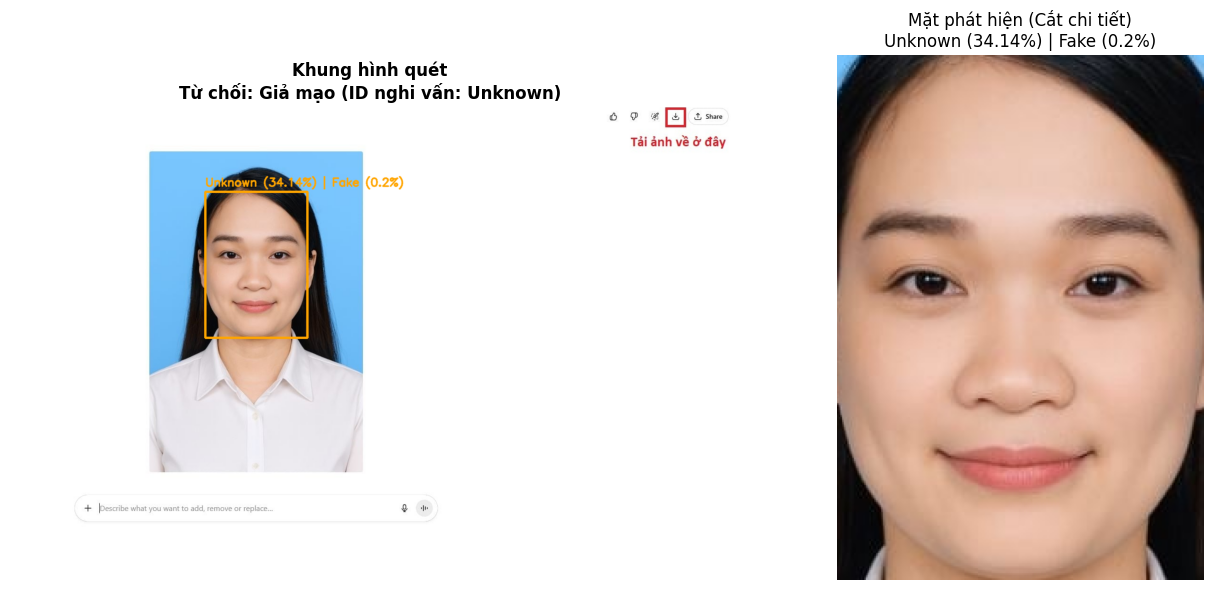


              KẾT QUẢ ĐIỂM DANH TEST
 Trạng thái Liveness : Fake (0.23%)
 ID Khớp             : Unknown
 Độ tương đồng (Sim) : 34.14%
 Kết luận chung      : Từ chối: Giả mạo (ID nghi vấn: Unknown)


In [11]:
import os
import sys
import glob
import cv2
import requests
import torch
import numpy as np
from numpy.linalg import norm
from tqdm import tqdm
import warnings
import matplotlib.pyplot as plt
import insightface
from insightface.app import FaceAnalysis
from insightface.utils import face_align

warnings.filterwarnings('ignore')

# =====================================================================
# 1. FIX ĐƯỜNG DẪN CAFFE CHO SILENT-FACE-ANTI-SPOOFING
# =====================================================================
repo_path = os.path.abspath("Silent-Face-Anti-Spoofing")
if repo_path not in sys.path:
    sys.path.append(repo_path)

import src.anti_spoof_predict as asp
from src.generate_patches import CropImage
from src.utility import parse_model_name

# Vá đè __init__ của Detection để trỏ đúng đường dẫn tuyệt đối
def patched_detection_init(self):
    caffemodel = os.path.join(repo_path, "resources", "detection_model", "Widerface-RetinaFace.caffemodel")
    deploy = os.path.join(repo_path, "resources", "detection_model", "deploy.prototxt")
    if not os.path.exists(deploy) or not os.path.exists(caffemodel):
        raise FileNotFoundError(f"Không tìm thấy file Caffe tại: {deploy}")
    self.detector = cv2.dnn.readNetFromCaffe(deploy, caffemodel)
    self.detector_confidence = 0.6

asp.Detection.__init__ = patched_detection_init

# Khởi tạo mô hình
device_id = 0 if torch.cuda.is_available() else -1
anti_spoof = asp.AntiSpoofPredict(device_id=device_id)
image_cropper = CropImage()

model_dir = os.path.join(repo_path, "resources", "anti_spoof_models")
available_models = glob.glob(os.path.join(model_dir, "*.pth"))
chosen_model = [m for m in available_models if "2.7_80x80" in m]
model_path = chosen_model[0] if chosen_model else available_models[0]

app = FaceAnalysis(name="buffalo_s", providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
app.prepare(ctx_id=0, det_size=(640, 640))

# =====================================================================
# 3. NẠP 500 ẢNH (1.png -> 500.png) VÀ CHẠY TEST
# =====================================================================
dataset_dir = "/kaggle/input/datasets/lukexng/aisanfaces/generated_yellow-stylegan2"

selected_paths = []
selected_ids = []
for i in range(1, 501):
    file_path = os.path.join(dataset_dir, f"{i}.png")
    if os.path.exists(file_path):
        selected_paths.append(file_path)
        selected_ids.append(str(i))

print(f"Đã tìm thấy {len(selected_paths)}/500 ảnh hợp lệ từ 1.png đến 500.png.")

# Nạp database với TTA
db = {}
add_to_database(db, selected_paths, selected_ids, app)
print(f"Đã nạp DB thành công ({len(db)} khuôn mặt. Có ID '100': {'100' in db})")

# Tải ảnh test từ đường link
url = "https://cdn.hstatic.net/files/200000966279/article/tao-anh-the-bang-chatgpt-5_79a2f347d0254d4a910cb07c00498cb1.jpg"
resp = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=15)
test_frame = cv2.imdecode(np.frombuffer(resp.content, np.uint8), cv2.IMREAD_COLOR)

results = process_multi_face_frame(
    test_frame, 
    db=db, 
    app=app, 
    det_thresh=0.5, 
    liveness_thresh=60.0, 
    recog_thresh=0.35, 
    max_faces=1, 
    check_liveness=True
)

# 2. XỬ LÝ VÀ VẼ KẾT QUẢ BẰNG MATPLOTLIB
if results:
    res = results[0]
    x1, y1, x2, y2 = res['bbox']
    liveness_label = res['liveness']['label']
    liveness_score = res['liveness']['score']
    matched_id = res['recognition']['matched_id']
    similarity = res['recognition']['similarity']
    status = res['status']
    
    # In thông tin text ra console
    print("\n" + "="*50)
    print("              KẾT QUẢ ĐIỂM DANH TEST")
    print("="*50)
    print(f" Trạng thái Liveness : {liveness_label} ({liveness_score}%)")
    print(f" ID Khớp             : {matched_id}")
    print(f" Độ tương đồng (Sim) : {similarity}%")
    print(f" Kết luận chung      : {status}")
    print("="*50)
    
    # Chọn màu khung (BGR): Xanh lá = Hợp lệ, Cam = Người lạ, Đỏ = Giả mạo
    if "Điểm danh thành công" in status:
        box_color = (0, 255, 0)      # Green
    elif matched_id == "Unknown":
        box_color = (0, 165, 255)    # Orange
    else:
        box_color = (0, 0, 255)      # Red
        
    # Tạo bản sao để vẽ
    display_img = test_frame.copy()
    cv2.rectangle(display_img, (x1, y1), (x2, y2), box_color, 4)
    
    label_text = f"{matched_id} ({similarity}%) | {liveness_label} ({liveness_score:.1f}%)"
    cv2.putText(
        display_img, 
        label_text, 
        (x1, max(30, y1 - 12)), 
        cv2.FONT_HERSHEY_SIMPLEX, 
        0.8, 
        box_color, 
        2, 
        cv2.LINE_AA
    )
    
    # Cắt vùng mặt khuôn mặt
    h_img, w_img = test_frame.shape[:2]
    crop_face = test_frame[max(0, y1):min(h_img, y2), max(0, x1):min(w_img, x2)]
    
    # Kiểm tra xem có ảnh gốc trong Database để so sánh đối chiếu không
    matched_db_img = None
    if matched_id != "Unknown":
        db_img_path = os.path.join(dataset_dir, f"{matched_id}.png")
        if os.path.exists(db_img_path):
            matched_db_img = cv2.imread(db_img_path)

    # 3. PLOT BẰNG MATPLOTLIB
    if matched_db_img is not None:
        # Trường hợp nhận diện được người trong DB: hiển thị 3 ảnh (Ảnh quét, Mặt crop, Ảnh mẫu DB)
        fig, axes = plt.subplots(1, 3, figsize=(18, 7))
        
        axes[0].imshow(cv2.cvtColor(display_img, cv2.COLOR_BGR2RGB))
        axes[0].set_title(f"Khung hình quét\n{status}", fontsize=12, fontweight='bold')
        axes[0].axis('off')
        
        axes[1].imshow(cv2.cvtColor(crop_face, cv2.COLOR_BGR2RGB))
        axes[1].set_title(f"Mặt phát hiện\nLiveness: {liveness_label} ({liveness_score}%)", fontsize=12)
        axes[1].axis('off')
        
        axes[2].imshow(cv2.cvtColor(matched_db_img, cv2.COLOR_BGR2RGB))
        axes[2].set_title(f"Mẫu trong DB: ID {matched_id}\nSimilarity: {similarity}%", fontsize=12, color='green')
        axes[2].axis('off')
    else:
        # Trường hợp Người lạ (Unknown) hoặc Giả mạo: hiển thị 2 ảnh
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        
        axes[0].imshow(cv2.cvtColor(display_img, cv2.COLOR_BGR2RGB))
        axes[0].set_title(f"Khung hình quét\n{status}", fontsize=12, fontweight='bold')
        axes[0].axis('off')
        
        axes[1].imshow(cv2.cvtColor(crop_face, cv2.COLOR_BGR2RGB))
        axes[1].set_title(f"Mặt phát hiện (Cắt chi tiết)\n{label_text}", fontsize=12)
        axes[1].axis('off')
        
    plt.tight_layout()
    plt.show()

else:
    print("Không phát hiện được bất kỳ khuôn mặt nào trong ảnh test.")

# In kết quả
print("\n" + "="*50)
print("              KẾT QUẢ ĐIỂM DANH TEST")
print("="*50)
if results:
    res = results[0]
    print(f" Trạng thái Liveness : {res['liveness']['label']} ({res['liveness']['score']}%)")
    print(f" ID Khớp             : {res['recognition']['matched_id']}")
    print(f" Độ tương đồng (Sim) : {res['recognition']['similarity']}%")
    if 'sim_with_100' in res['recognition']:
        print(f" Sim riêng với ID 100: {res['recognition']['sim_with_100']}%")
    print(f" Kết luận chung      : {res['status']}")
else:
    print(" Không tìm thấy khuôn mặt.")
print("="*50)